In [38]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier,plot_tree
import matplotlib.pyplot as plt

In [39]:
df=pd.read_csv("/home/backup/ml_datasets/OnlineRetail1.csv",encoding='cp1252')
print(df)
df=df.dropna(subset=['CustomerID'])
df=df[(df['Quantity']>0)&(df['UnitPrice']>0)]
df['TotalSpend']=df['Quantity']*df['UnitPrice']
customer_df=df.groupby('CustomerID').agg({
    'Quantity':'sum',
    'UnitPrice':'mean',
    'TotalSpend':'sum',
    'Country':'first'
}).reset_index()

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

             InvoiceDate  UnitPrice  CustomerID         Country  
0       0

In [40]:
threshold=customer_df['TotalSpend'].median()
customer_df['HighValue']=(customer_df['TotalSpend']>threshold).astype(int)
#Encode categorcical data
le=LabelEncoder()
customer_df['Country']=le.fit_transform(customer_df['Country'])


In [41]:
x=customer_df[['Quantity','UnitPrice','Country']]
y=customer_df['HighValue']

In [42]:
model=DecisionTreeClassifier(criterion='entropy',max_depth=4)
model.fit(x,y)


DecisionTreeClassifier(criterion='entropy', max_depth=4)

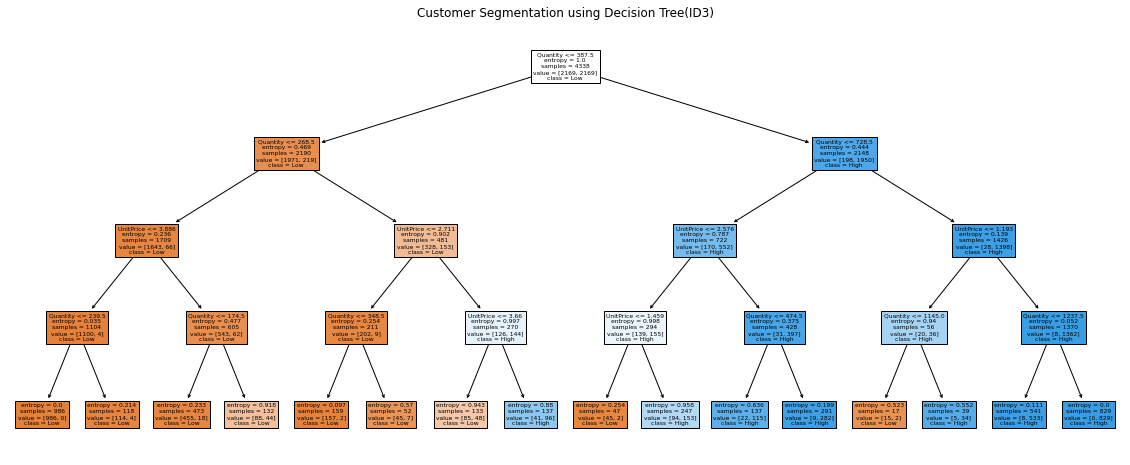

In [43]:
plt.figure(figsize=(20,8))
plot_tree(model,
          feature_names=x.columns,
          class_names=['Low','High'],
          filled=True)
plt.title("Customer Segmentation using Decision Tree(ID3)")
plt.show()

In [44]:
importance=pd.Series(model.feature_importances_,index=x.columns)
print("\nFeature Importance:\n",importance.sort_values(ascending=False))


Feature Importance:
 Quantity     0.86527
UnitPrice    0.13473
Country      0.00000
dtype: float64
